# Lab 4 — HydroGrowNet / Batavia Lettuce
## Mismo código de Lab3/redFFBP
**Predicción:** peso total de la lechuga en gramos.


In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import zipfile
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

In [9]:
import re
base=Path.cwd()
zp=base.parent/"datasets"/"all_months_sensory_data.zip" if base.name=="notebooks" else base/"datasets"/"all_months_sensory_data.zip"
out=zp.parent/"hydro"
out.mkdir(exist_ok=True)
with zipfile.ZipFile(zp) as z: z.extractall(out)

def cosecha(archivo):
    xls=pd.ExcelFile(archivo)
    hoja=[h for h in xls.sheet_names if "Harvest" in h][0]
    raw=pd.read_excel(archivo,sheet_name=hoja,header=None)
    fila=next(i for i in range(len(raw))
              if raw.iloc[i].astype(str).str.contains("Total weight",case=False,na=False).any())
    headers=[str(v).strip() if pd.notna(v) else "x"+str(j)
             for j,v in enumerate(raw.iloc[fila])]
    t=raw.iloc[fila+1:].copy()
    t.columns=headers
    def buscar(txt):
        return next(c for c in t.columns if txt.lower() in str(c).lower())
    d=pd.DataFrame({
        "total_weight":pd.to_numeric(t[buscar("Total weight")],errors="coerce"),
        "plant_height":pd.to_numeric(t[buscar("Plant height")],errors="coerce"),
        "shoot_length":pd.to_numeric(t[buscar("Shoot length")],errors="coerce"),
        "root_length":pd.to_numeric(t[buscar("Root length")],errors="coerce"),
        "stem_diameter":pd.to_numeric(t[buscar("Stem diameter")],errors="coerce"),
        "leaves":pd.to_numeric(t[buscar("leaves")],errors="coerce")
    })
    return d.dropna()

df=pd.concat([cosecha(a) for a in sorted(out.glob("*.xlsx"))],ignore_index=True)
print(df.head())
print("Plantas utiles:",len(df))

   total_weight  plant_height  shoot_length  root_length  stem_diameter  \
0         243.0          42.0          13.5         28.5            1.7   
1         241.0          54.0          10.5         43.5            2.0   
2         251.0          62.0          13.5         48.5            2.0   
3         200.0          55.0          13.5         41.5            2.0   
4         200.0          66.0          14.0         52.0            2.0   

   leaves  
0   210.0  
1   200.0  
2   212.0  
3   185.0  
4   178.0  
Plantas utiles: 222


total_weight     1.000000
leaves           0.963586
shoot_length     0.658641
plant_height     0.341788
root_length      0.150471
stem_diameter    0.099693
Name: total_weight, dtype: float64


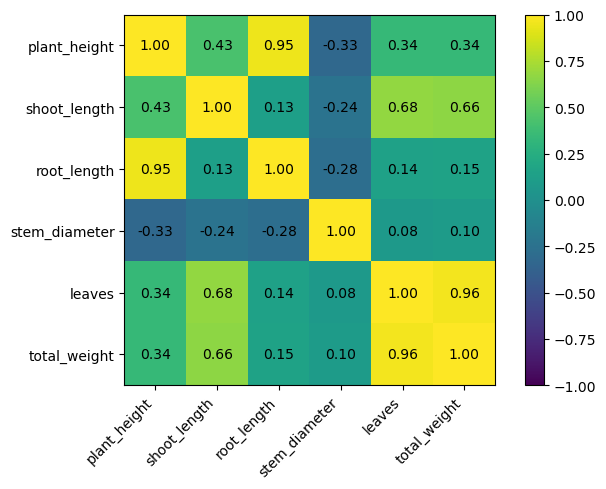

In [10]:
cols=['plant_height', 'shoot_length', 'root_length', 'stem_diameter', 'leaves', 'total_weight']
corr=df[cols].corr()
print(corr['total_weight'].sort_values(ascending=False))

fig,ax=plt.subplots(figsize=(7,5))
im=ax.imshow(corr,vmin=-1,vmax=1)
ax.set_xticks(range(len(cols)),cols,rotation=45,ha="right")
ax.set_yticks(range(len(cols)),cols)
for i in range(len(cols)):
    for j in range(len(cols)):
        ax.text(j,i,f"{corr.iloc[i,j]:.2f}",ha="center",va="center")
fig.colorbar(im)
plt.tight_layout()
plt.show()

In [11]:
X = df[['plant_height', 'shoot_length', 'root_length', 'stem_diameter', 'leaves']].values
y = df[['total_weight']].values

# 60% entrenamiento / 40% prueba
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.40, random_state=42
)

scaler_X = StandardScaler()
scaler_y = StandardScaler()

X_train = scaler_X.fit_transform(X_train)
X_test = scaler_X.transform(X_test)
y_train_norm = scaler_y.fit_transform(y_train)
y_test_norm = scaler_y.transform(y_test)

print("Entrenamiento:", len(X_train))
print("Prueba:", len(X_test))

Entrenamiento: 133
Prueba: 89


In [12]:
# MISMA IMPLEMENTACION DE Lab3/redFFBP
def ReLu(x):
    return np.maximum(0, x)

class Capa:
    def __init__(self, entradas, neuronas, activacion=None, bias=False):
        self.entradas = entradas
        self.neuronas = neuronas
        self.activacion = activacion
        self.bias = bias

        self.pesos = np.random.randn(entradas, neuronas) * 0.1

        if bias:
            self.b = np.zeros((1, neuronas))
        else:
            self.b = None

    def feed_forward(self, X):
        self.entrada = X
        self.z = X @ self.pesos

        if self.bias:
            self.z += self.b

        if self.activacion is not None:
            self.salida = self.activacion(self.z)
        else:
            self.salida = self.z

        return self.salida

    def backward(self, ultima=False, error=None,
                 delta_siguiente=None, pesos_siguientes=None):

        if ultima:
            self.delta = error
        else:
            self.delta = delta_siguiente @ pesos_siguientes.T

            if self.activacion == ReLu:
                self.delta *= (self.z > 0)

        self.grad_pesos = self.entrada.T @ self.delta

        if self.bias:
            self.grad_bias = np.sum(
                self.delta,
                axis=0,
                keepdims=True
            )

        return self.delta

In [13]:
np.random.seed(42)

capa1 = Capa(
    entradas=5,
    neuronas=13,
    activacion=ReLu,
    bias=True
)

capa2 = Capa(
    entradas=13,
    neuronas=1,
    activacion=None,
    bias=True
)

epocas = 500

alpha = 0.02 / len(X_train)

historial_perdida = []

for epoca in range(epocas):

    # Feed Forward
    salida1 = capa1.feed_forward(X_train)
    resultado = capa2.feed_forward(salida1)

    # Error
    error = resultado - y_train_norm

    # Perdida
    perdida = 0.5 * np.mean(error ** 2)
    historial_perdida.append(perdida)

    # Backpropagation
    delta2 = capa2.backward(
        ultima=True,
        error=error
    )

    delta1 = capa1.backward(
        ultima=False,
        delta_siguiente=delta2,
        pesos_siguientes=capa2.pesos
    )

    # Actualizacion de pesos
    capa1.pesos -= alpha * capa1.grad_pesos
    capa2.pesos -= alpha * capa2.grad_pesos

    # Actualizacion de bias
    capa1.b -= alpha * capa1.grad_bias
    capa2.b -= alpha * capa2.grad_bias

    if epoca == 0 or (epoca + 1) % 50 == 0:
        print("Epoca:", epoca + 1, "- Perdida:", perdida)

salida_test = capa1.feed_forward(X_test)
pred_test_norm = capa2.feed_forward(salida_test)

pred_test = scaler_y.inverse_transform(pred_test_norm)
y_test_real = scaler_y.inverse_transform(y_test_norm)

Epoca: 1 - Perdida: 0.517021168012388
Epoca: 50 - Perdida: 0.40486172250213637
Epoca: 100 - Perdida: 0.23579232387021085
Epoca: 150 - Perdida: 0.10503756642991942
Epoca: 200 - Perdida: 0.05999962622847623
Epoca: 250 - Perdida: 0.047122160080374655
Epoca: 300 - Perdida: 0.042160007598793466
Epoca: 350 - Perdida: 0.039491676429271115
Epoca: 400 - Perdida: 0.03787788561953311
Epoca: 450 - Perdida: 0.03685845360213173
Epoca: 500 - Perdida: 0.03617244959858939


R² = 0.9252389514163037
R = 0.9623383637800071
MAE = 11.05065102617997
RMSE = 15.697426566264909


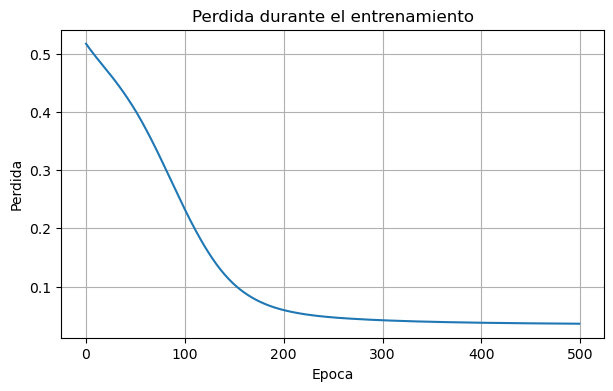

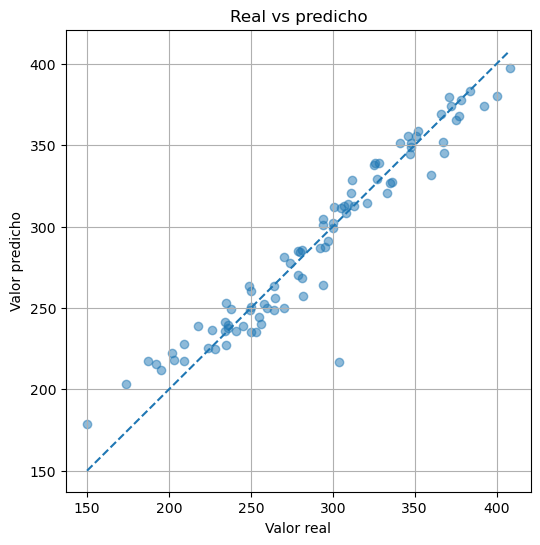

In [14]:
r2 = r2_score(y_test_real, pred_test)
r = np.corrcoef(y_test_real.ravel(), pred_test.ravel())[0, 1]
mae = mean_absolute_error(y_test_real, pred_test)
rmse = np.sqrt(mean_squared_error(y_test_real, pred_test))

print("R² =", r2)
print("R =", r)
print("MAE =", mae)
print("RMSE =", rmse)

plt.figure(figsize=(7,4))
plt.plot(historial_perdida)
plt.xlabel("Epoca")
plt.ylabel("Perdida")
plt.title("Perdida durante el entrenamiento")
plt.grid()
plt.show()

plt.figure(figsize=(6,6))
plt.scatter(y_test_real, pred_test, alpha=0.5)
a=min(y_test_real.min(),pred_test.min())
b=max(y_test_real.max(),pred_test.max())
plt.plot([a,b],[a,b],"--")
plt.xlabel("Valor real")
plt.ylabel("Valor predicho")
plt.title("Real vs predicho")
plt.grid()
plt.show()